# CO × Lyα: maps, power spectra, and S/N
Run from top to bottom in your LiLa/nbodykit environment. This notebook is self-contained: it does not import `co_lya_sn.py` or your Cartesian power estimator. It loads the CO cube produced by your mocker and uses matching FFTPower bins throughout.

Edit the paths and noise settings below. Zero noise gives **sample-variance-only** S/N. The Gaussian calculation assumes independent spherical bins and uncorrelated tracer noise; it does not include a survey window, anisotropic beam, reconstruction transfer function, or non-Gaussian covariance.

Both cubes must trace the **same simulation realization, volume, redshift, origin and axes**. Matching sizes alone is insufficient: an independent Peak Patch realization cannot be cross-correlated with ASTRID to obtain a physical cross signal. `mode="1d"` here means the spherically averaged **3D** spectrum, not the sightline 1D spectrum.

In [5]:
from copy import copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from lila import mock_lya
from lila.stats import Stats
from nbodykit.lab import ArrayMesh, FFTPower

ModuleNotFoundError: No module named 'lila'

## 1. Paths and settings

In [ ]:
lya_folder = Path("/projects/pbreysse/lya_forest_CO/lya_storage/Lyman-alpha-ASTRID_z2.5_unzipped/Lyman-alpha-ASTRID_z2.5")
co_file = "/users/jiawenfan/work/lya_CO/limlam_cartesian_v2_simplified/co_li_cartesian.npz"
box = np.array([250., 250., 250.])  # cMpc/h; must match CO metadata

kmin, kmax, dk = 0.03, 1.0, 0.05  # h/cMpc
volume_ratio = 1.0  # survey volume / box volume; mode-count scaling only

# Reproduce the TWO transpositions in your original notebook.
# Set final_transpose=(0, 1, 2) if the LiLa output is already aligned.
load_transpose = (1, 0, 2)
final_transpose = (1, 0, 2)

noise_co = 0.0   # microK^2 (cMpc/h)^3
noise_lya = 0.0  # (cMpc/h)^3 for delta_F
# Scalars, arrays matching the FFT bins, or functions of k are accepted.
# CO white noise: noise_co = sigma_voxel_microK**2 * voxel_volume_cmpch3
# The voxel volume must correspond to the supplied noise RMS.
output_file = "co_lya_sn_results.npz"

## 2. Load and match the cubes
Lyα is block-averaged to the CO grid. This changes its small-scale power, so the same averaged cube is used for the Lyα auto-spectrum and cross-spectrum. No extra smoothing is applied to CO.

In [2]:
def rebin_mean(field, shape):
    """Average integer-sized blocks, one output x slab at a time."""
    shape = np.asarray(shape, dtype=int)
    old_shape = np.asarray(field.shape)
    if np.any(old_shape % shape):
        raise ValueError("Ly-alpha dimensions must be integer multiples of CO dimensions")
    if np.array_equal(old_shape, shape):
        return field
    fx, fy, fz = old_shape // shape
    nx, ny, nz = shape
    result = np.empty(tuple(shape), dtype=np.float32)
    for i in range(nx):
        slab = field[i * fx:(i + 1) * fx]
        result[i] = slab.reshape(fx, ny, fy, nz, fz).mean(
            axis=(0, 2, 4), dtype=np.float64)
    return result

In [4]:
with np.load(co_file) as f:
    Tco = np.array(f["map_cube"], dtype=np.float32)

lya_mock = mock_lya.MockLya(
    noiseless_file=str(lya_folder / "map_ASTRID_true_0.25_z2.5.hdf5"),
    spec_file=str(lya_folder / "spectra_ASTRID_noiseless_z2.5_1000_voxels.hdf5"),
    boxsize=box.tolist(), dperp=2.5, sn=2,
    transpose=load_transpose, flux_mode=False, silent_mode=False,
)

dF = np.transpose(lya_mock.get_map_noiseless(), final_transpose)
dF = np.ascontiguousarray(rebin_mean(dF, Tco.shape), dtype=np.float32)

# Give LiLa the same rebinned field used in the cross spectrum.
matched_lya = copy(lya_mock)
matched_lya.noiseless_map = dF - dF.mean()
matched_lya.Nmesh = list(dF.shape)
matched_lya.flux_mode = False

print("Grid:", Tco.shape, "Box [cMpc/h]:", box)
print("CO mean [microK]:", Tco.mean())
print("Lyα mean delta_F:", dF.mean())

[ 000000.00 ]   0: 10-04 23:48  MockLya         INFO     Starting
[ 000000.00 ]   0: 10-04 23:48  MockLya         INFO     dperp = 2.5


Grid: (1000, 1000, 1000) Box [cMpc/h]: [250. 250. 250.]
CO mean [microK]: 0.7245254
Lyα mean delta_F: -1.5552146e-08


## 3. Side-by-side slab averages
Both panels average the same z interval. CO contrast enhancement affects only the display. Lyα shows transmitted-flux contrast, not H I density.

In [3]:
import matplotlib.colors as colors
iz = Tco.shape[2] // 2
half_width = 5
slab = slice(max(0, iz-half_width), min(Tco.shape[2], iz+half_width))
co_image = Tco[:, :, slab].mean(axis=2)
lya_image = dF[:, :, slab].mean(axis=2)
# For full-depth projections, use Tco.mean(axis=2) and dF.mean(axis=2).

positive = co_image[np.isfinite(co_image) & (co_image > 0)]
vmax = np.percentile(positive, 95) if positive.size else 1.0
extent = [0, box[0], 0, box[1]]
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
vmin = np.percentile(positive, 1)  # Log scale needs vmin > 0

im0 = ax[0].imshow(
    co_image.T,
    origin="lower",
    extent=extent,
    cmap="inferno",
    norm=colors.LogNorm(vmin=vmin, vmax=vmax, clip=True)
)
im1 = ax[1].imshow(lya_image.T, origin="lower", extent=extent, cmap="RdBu_r")
ax[0].set_title("CO — slab average")
ax[1].set_title(r"Ly$\alpha$ forest — same slab")
fig.colorbar(
    im0, ax=ax[0],
    label=r"$T_{\rm CO}$ [$\mu$K]",
    extend="max"
)
fig.colorbar(im1, ax=ax[1], label=r"$\delta_F$")
for a in ax:
    a.set_xlabel(r"$x$ [cMpc/$h$]")
ax[0].set_ylabel(r"$y$ [cMpc/$h$]")
plt.tight_layout()
plt.show()

NameError: name 'Tco' is not defined

## 4. All three spectra with identical bins
CO remains in μK after mean subtraction. Halo shot power remains in its auto-spectrum. Negative cross-power is retained.

In [4]:
k_nyquist = np.min(np.pi * np.asarray(Tco.shape) / box)
if not (0 < kmin < kmax <= 0.5 * k_nyquist):
    raise ValueError("Choose 0 < kmin < kmax <= half the smallest Nyquist frequency")
settings = dict(mode="1d", BoxSize=box, kmin=kmin, kmax=kmax, dk=dk)

lya_stats = Stats(mock_lya=matched_lya, kmin=kmin, kmax=kmax, dk=dk)
auto_lya = lya_stats.get_lya_pk(mode="1d").power

co_mesh = ArrayMesh(Tco - Tco.mean(), BoxSize=box)
lya_mesh = ArrayMesh(matched_lya.noiseless_map, BoxSize=box)
auto_co = FFTPower(first=co_mesh, **settings).power
cross = FFTPower(first=co_mesh, second=lya_mesh, **settings).power

np.testing.assert_allclose(auto_co.edges["k"], cross.edges["k"])
np.testing.assert_allclose(auto_lya.edges["k"], cross.edges["k"])
np.testing.assert_array_equal(auto_co["modes"], cross["modes"])
np.testing.assert_array_equal(auto_lya["modes"], cross["modes"])
print("Shared bins:", len(cross["k"]))

NameError: name 'Tco' is not defined

## 5. Noise and S/N
With full Fourier mode counts (including both signs of **k**),
$$\sigma_\times^2=\frac{P_\times^2+(P_{CO}+N_{CO})(P_F+N_F)}{N_{modes}},\qquad (S/N)_{total}=\sqrt{\sum_i(P_{\times,i}/\sigma_{\times,i})^2}.$$
Auto-spectrum errors are $\sqrt{2/N_{modes}}(P+N)$. Noise is supplied explicitly: setting `lya_mock.sn` alone does not add noise to this calculation. The maps used above are noiseless. Do not add a second copy of CO halo shot power to `noise_co`.

In [7]:
def signal_to_noise(k, Pco, Plya, Pcross, modes, noise_co, noise_lya,
                    volume_ratio=1.0):
    """Gaussian S/N using FULL Fourier mode counts (including +/- k).

    Noise: nonnegative scalar, array matching k, or callable evaluated at k.
    volume_ratio = survey volume / map volume; this is only a mode-count
    rescaling, not an explicit survey-window calculation.
    """
    Nco = noise_co(k) if callable(noise_co) else noise_co
    Nlya = noise_lya(k) if callable(noise_lya) else noise_lya
    Nco = np.broadcast_to(np.asarray(Nco, dtype=float), k.shape)
    Nlya = np.broadcast_to(np.asarray(Nlya, dtype=float), k.shape)
    if np.any(Nco < 0) or np.any(Nlya < 0) or volume_ratio <= 0:
        raise ValueError("Noise powers must be nonnegative and volume_ratio positive")
    Nm = modes * volume_ratio
    valid = ((k > 0) & (Nm > 0) & (Pco > 0) & (Plya > 0)
             & np.isfinite(k + Pco + Plya + Pcross + Nco + Nlya))
    k, Pco, Plya, Pcross, Nm, Nco, Nlya = [
        a[valid] for a in (k, Pco, Plya, Pcross, Nm, Nco, Nlya)]
    if k.size == 0:
        raise ValueError("No common valid bins remain")

    # Halo shot noise is already included in Pco; do not add it again.
    sigma_cross = np.sqrt(((Pco + Nco) * (Plya + Nlya) + Pcross**2) / Nm)
    sigma_co = np.sqrt(2 / Nm) * (Pco + Nco)
    sigma_lya = np.sqrt(2 / Nm) * (Plya + Nlya)
    sn_cross = np.abs(Pcross) / sigma_cross
    sn_co = Pco / sigma_co
    sn_lya = Plya / sigma_lya

    return dict(k=k, P_CO=Pco, P_F=Plya, P_CO_F=Pcross,
                r=Pcross / np.sqrt(Pco * Plya), modes=Nm,
                noise_CO=Nco, noise_F=Nlya,
                sigma_cross=sigma_cross, sigma_CO=sigma_co, sigma_F=sigma_lya,
                sn_cross=sn_cross, sn_CO=sn_co, sn_F=sn_lya,
                sn_cross_total=np.sqrt(np.sum(sn_cross**2)),
                sn_CO_total=np.sqrt(np.sum(sn_co**2)),
                sn_F_total=np.sqrt(np.sum(sn_lya**2)), valid_bins=valid)

In [8]:
result = signal_to_noise(
    k=np.asarray(cross["k"]),
    Pco=np.asarray(auto_co["power"].real),
    Plya=np.asarray(auto_lya["power"].real),
    Pcross=np.asarray(cross["power"].real),
    modes=np.asarray(cross["modes"]),
    noise_co=noise_co, noise_lya=noise_lya, volume_ratio=volume_ratio,
)
result.update(k_edges=np.asarray(cross.edges["k"]), boxsize_cmpch=box,
              volume_ratio=volume_ratio, redshift=float(lya_mock.z),
              load_transpose=np.array(load_transpose), final_transpose=np.array(final_transpose))
for name in ("CO", "F", "cross"):
    print(f"{name} total S/N = {result['sn_' + name + '_total']:.3f}")
np.savez(output_file, **result)
print("Saved:", output_file)

CO total S/N = 352.166
F total S/N = 352.166
cross total S/N = 245.764
Saved: co_lya_sn_results.npz


## 6. Spectra, correlation coefficient, and S/N
To plot a saved run without redoing the FFTs, import NumPy and Matplotlib, load `result = np.load("co_lya_sn_results.npz")`, then run these plotting cells.

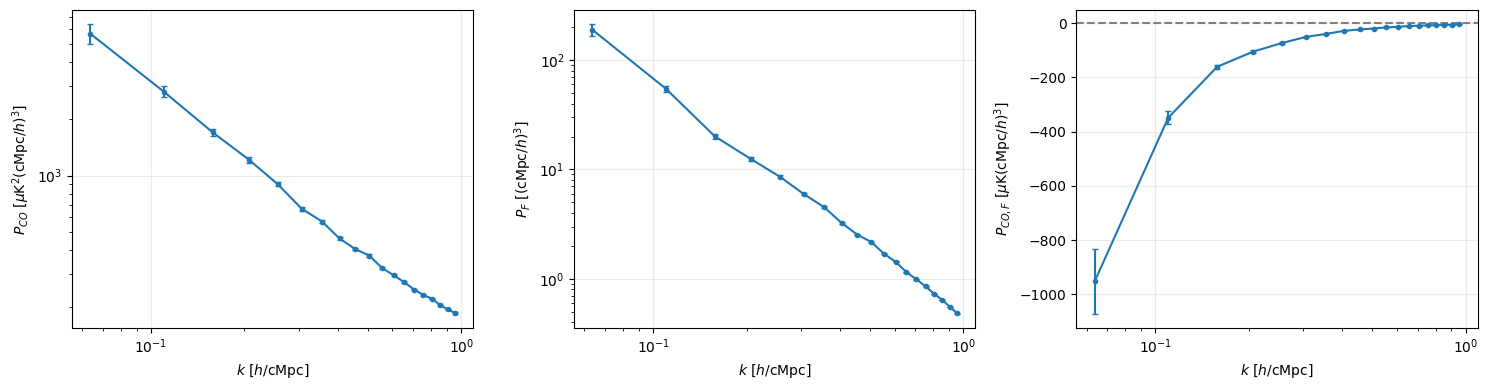

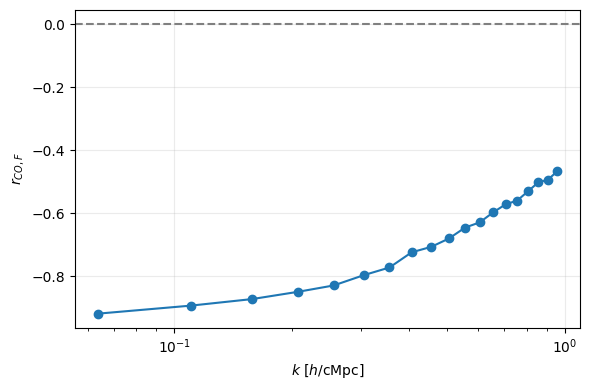

In [9]:
k = result["k"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, power, error, label in zip(
    ax, ["P_CO", "P_F", "P_CO_F"], ["sigma_CO", "sigma_F", "sigma_cross"],
    [r"$P_{CO}$ [$\mu$K$^2$(cMpc/$h$)$^3$]",
     r"$P_F$ [(cMpc/$h$)$^3$]", r"$P_{CO,F}$ [$\mu$K(cMpc/$h$)$^3$]"]):
    a.errorbar(k, result[power], yerr=result[error], fmt="o-", ms=3, capsize=2)
    a.set_xscale("log")
    a.set_xlabel(r"$k$ [$h$/cMpc]")
    a.set_ylabel(label)
    a.grid(alpha=0.25)
ax[0].set_yscale("log")
ax[1].set_yscale("log")
ax[2].axhline(0, color="gray", ls="--")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.semilogx(k, result["r"], "o-")
plt.axhline(0, color="gray", ls="--")
plt.xlabel(r"$k$ [$h$/cMpc]")
plt.ylabel(r"$r_{CO,F}$")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

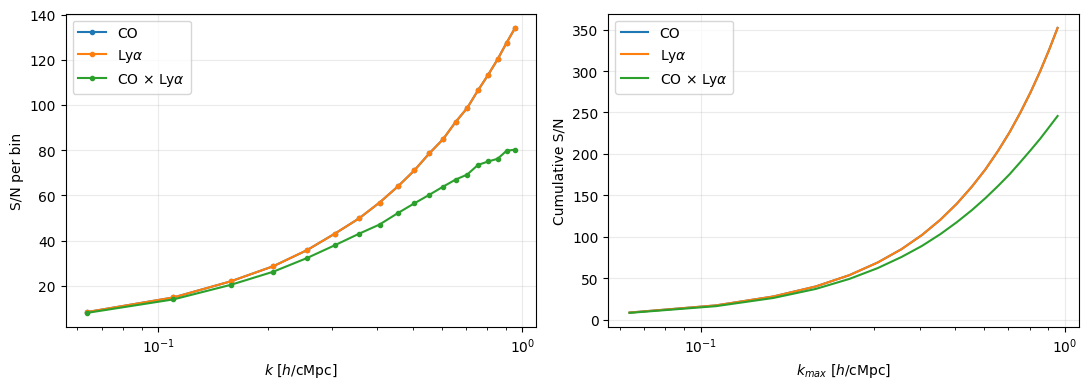

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = np.argsort(result["k"])
k = result["k"][order]
for key, label in [("sn_CO", "CO"), ("sn_F", r"Ly$\alpha$"), ("sn_cross", r"CO × Ly$\alpha$")]:
    sn = result[key][order]
    ax[0].plot(k, sn, "o-", ms=3, label=label)
    ax[1].plot(k, np.sqrt(np.cumsum(sn**2)), label=label)
for a in ax:
    a.set_xscale("log")
    a.grid(alpha=0.25)
    a.legend()
ax[0].set_xlabel(r"$k$ [$h$/cMpc]")
ax[1].set_xlabel(r"$k_{max}$ [$h$/cMpc]")
ax[0].set_ylabel("S/N per bin")
ax[1].set_ylabel("Cumulative S/N")
plt.tight_layout()
plt.show()